# Projet Goutte d'Eau – Analyse des données et modèle

Ce notebook présente toute la démarche data du MVP, étape par étape :

1. Exploration des données brutes
2. Qualité des données (manquants, aberrants, doublons, trous)
3. Nettoyage et agrégation journalière
4. Analyse univariée
5. Analyse bivariée (liens avec la pluie du lendemain)
6. Préparation des variables du modèle
7. Modélisation et évaluation
8. Conclusion

**Station** : station Paris 20e – Porte de Vincennes (000EW), choisie avec `choisir_station.py` car c'est la plus complète pour la pluie.
**Question** : quel est le risque qu'il tombe au moins 1 mm de pluie le jour J ?

> Avant de lancer ce notebook : exécuter `python collecte.py` (la base `data/meteo.db` doit exister).
> Les règles de nettoyage et les variables sont importées depuis `nettoyage.py` et `features.py` :
> le notebook et les scripts utilisent donc exactement le même traitement.

In [1]:
import os
import sqlite3
import warnings

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay)

import nettoyage
from features import preparer, COLONNES_MODELE, SEUIL_PLUIE_MM
from entrainement import nouveau_modele, choisir_seuil_alerte

pd.set_option("display.max_columns", 30)
plt.rcParams["figure.figsize"] = (9, 4)
os.makedirs("figures", exist_ok=True)   # les graphiques utiles au rapport y sont enregistrés
warnings.filterwarnings("ignore", message="Skipping features")  # variable non mesurée : ignorée

conn = sqlite3.connect("data/meteo.db")

## 1. Exploration des données brutes

Les mesures brutes viennent de l'API Infoclimat (table `raw_observations`).
On regarde leur volume, la période couverte et la fréquence des mesures.

In [2]:
brut = nettoyage.charger_brut(conn)
print("Nombre de mesures :", len(brut))
print("Période couverte  :", brut["dh_utc"].min(), "->", brut["dh_utc"].max())
brut.head()

Nombre de mesures : 143923
Période couverte  : 2024-01-01 00:00:00 -> 2026-10-23 16:30:00


,station,dh_utc,temperature,pression,humidite,vent_moyen,vent_rafales,pluie_1h,pluie_3h
0,000EW,2024-01-01 00:00:00,8.3,1006.2,79.0,5.6,None,0.0,0.0
1,000EW,2024-01-01 00:10:00,8.3,1006.2,79.0,8.0,None,NaN,NaN
2,000EW,2024-01-01 00:20:00,8.3,1006.3,79.0,6.4,None,NaN,NaN
3,000EW,2024-01-01 00:30:00,8.3,1006.3,79.0,5.6,None,NaN,NaN
4,000EW,2024-01-01 00:40:00,8.3,1006.3,79.0,5.6,None,NaN,NaN


In [3]:
brut.dtypes

station                    str
dh_utc          datetime64[us]
temperature            float64
pression               float64
humidite               float64
vent_moyen             float64
vent_rafales            object
pluie_1h               float64
pluie_3h               float64
dtype: object

In [4]:
# Intervalle entre deux mesures consécutives (en minutes)
ecart = brut["dh_utc"].diff().dt.total_seconds() / 60
print("Intervalle le plus fréquent :", ecart.mode()[0], "minutes")
print("Mesures par jour (médiane) :", brut.groupby(brut["dh_utc"].dt.date).size().median())
ecart.value_counts().head(5)

Intervalle le plus fréquent : 10.0 minutes
Mesures par jour (médiane) : 144.0


dh_utc
10.0    143207
20.0       608
30.0        44
40.0        19
50.0         8
Name: count, dtype: int64

In [5]:
brut.describe().round(1)

,dh_utc,temperature,pression,humidite,vent_moyen,pluie_1h,pluie_3h
count,143923,143478.0,143923.0,143480.0,143471.0,24002.0,24002.0
mean,2025-06-01 03:15:42.141283,14.8,1015.4,70.9,2.4,0.1,0.1
min,2024-01-01 00:00:00,-3.7,974.3,17.0,0.0,0.0,0.0
25%,2024-09-26 01:55:00,9.8,1010.5,60.0,0.0,0.0,0.0
50%,2025-06-04 04:40:00,14.3,1016.2,75.0,0.8,0.0,0.0
75%,2026-02-10 14:55:00,19.6,1021.3,84.0,4.0,0.0,0.0
max,2026-10-23 16:30:00,40.9,1042.1,100.0,22.5,15.6,25.0
std,NaN,7.3,9.2,16.5,2.9,0.5,0.6


**Lecture** : la station envoie une mesure environ toutes les 10 minutes. `describe()` donne une
première idée des ordres de grandeur et permet de repérer d'éventuelles valeurs impossibles
(minimum ou maximum aberrant).

## 2. Qualité des données

### 2.1 Valeurs manquantes

In [6]:
manquants = (brut.isna().mean() * 100).round(1).sort_values(ascending=False)
manquants.to_frame("% de valeurs manquantes")

,% de valeurs manquantes
vent_rafales,100.0
pluie_3h,83.3
pluie_1h,83.3
humidite,0.3
temperature,0.3
vent_moyen,0.3
station,0.0
pression,0.0
dh_utc,0.0


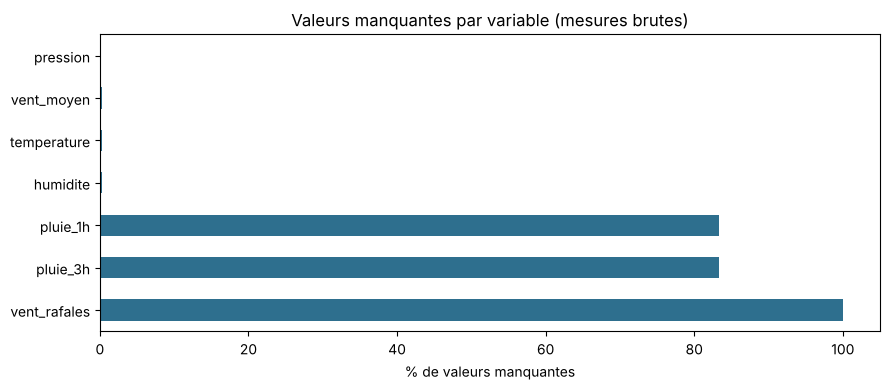

In [7]:
manquants.drop(["station", "dh_utc"]).plot(kind="barh", color="#2E6F8E")
plt.xlabel("% de valeurs manquantes")
plt.title("Valeurs manquantes par variable (mesures brutes)")
plt.tight_layout()
plt.show()

**Lecture** : une variable presque entièrement vide n'est pas mesurée par la station ; elle sera
ignorée automatiquement par le modèle. `pluie_3h` sert seulement de secours si `pluie_1h` manque.

### 2.2 Doublons et valeurs aberrantes
On compare chaque mesure à une plage de valeurs physiquement plausibles (définie dans `nettoyage.py`).

In [8]:
print("Doublons (même station, même date-heure) :", brut.duplicated(subset=["station", "dh_utc"]).sum())

brut_propre, nb_supprimees = nettoyage.supprimer_aberrants(brut)
pd.DataFrame({"plage plausible": nettoyage.LIMITES, "valeurs supprimées": nb_supprimees})

Doublons (même station, même date-heure) : 0


,plage plausible,valeurs supprimées
temperature,"(-30, 50)",0
pression,"(950, 1060)",0
humidite,"(0, 100)",0
vent_moyen,"(0, 150)",0
vent_rafales,"(0, 250)",0
pluie_1h,"(0, 150)",0
pluie_3h,"(0, 300)",0


### 2.3 Continuité dans le temps
Un jour avec trop peu de mesures (panne de la station, coupure réseau) ne donne pas une moyenne fiable.

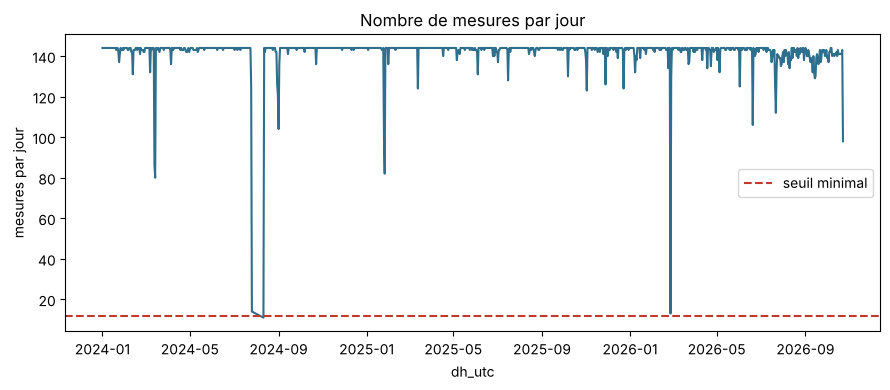

Jours du calendrier       : 1027
Jours avec des mesures    : 1012
Jours sous le seuil minimal : 1


In [9]:
mesures_par_jour = brut.groupby(brut["dh_utc"].dt.date).size()
mesures_par_jour.plot(color="#2E6F8E")
plt.axhline(nettoyage.MIN_MESURES_PAR_JOUR, color="#C0392B", linestyle="--", label="seuil minimal")
plt.ylabel("mesures par jour")
plt.title("Nombre de mesures par jour")
plt.legend()
plt.tight_layout()
plt.show()

calendrier = pd.date_range(brut["dh_utc"].min().date(), brut["dh_utc"].max().date(), freq="D")
print("Jours du calendrier       :", len(calendrier))
print("Jours avec des mesures    :", len(mesures_par_jour))
print("Jours sous le seuil minimal :", (mesures_par_jour < nettoyage.MIN_MESURES_PAR_JOUR).sum())

## 3. Nettoyage et agrégation journalière

Règles appliquées (identiques à `nettoyage.py`) :
- suppression des doublons et des valeurs hors plage plausible ;
- agrégation par jour : moyenne, minimum ou maximum selon la variable ;
- **pluie** : `pluie_1h` est un cumul glissant sur 1 h répété à chaque mesure ; on garde la dernière
  mesure de chaque heure puis on additionne les 24 heures (sinon la même pluie serait comptée ~6 fois) ;
- suppression des jours avec moins de 12 mesures.

In [10]:
jours = nettoyage.agreger_par_jour(brut_propre)
print("Mesures brutes :", len(brut), "-> jours nettoyés :", len(jours),
      f"({len(brut) / len(jours):.0f} fois moins de lignes)")
jours.head()

Mesures brutes : 143923 -> jours nettoyés : 1011 (142 fois moins de lignes)


,date,temp_moy,temp_min,temp_max,pression_moy,humidite_moy,vent_moy,rafales_max,pluie_mm
0,2024-01-01,9.01,7.2,10.9,1008.21,80.68,4.98,NaN,6.0
1,2024-01-02,11.63,10.7,12.7,997.50,87.15,9.33,NaN,10.0
2,2024-01-03,11.44,9.7,13.3,999.11,81.01,5.81,NaN,4.0
3,2024-01-04,10.35,8.6,11.8,1005.12,82.75,3.69,NaN,0.0
4,2024-01-05,8.70,7.2,10.5,1003.65,77.97,1.96,NaN,0.2


In [11]:
# Contrôle : la table enregistrée par nettoyage.py doit contenir les mêmes données
en_base = pd.read_sql("SELECT * FROM daily_observations", conn)
print("Table daily_observations :", len(en_base), "jours")
jours.count().to_frame("jours renseignés")

Table daily_observations : 1011 jours


,jours renseignés
date,1011
temp_moy,1011
temp_min,1011
temp_max,1011
pression_moy,1011
humidite_moy,1011
vent_moy,1011
rafales_max,0
pluie_mm,1006


## 4. Analyse univariée

### 4.1 La variable cible : jour de pluie (≥ 1 mm)

Jours de pluie : 27.8%  |  jours secs : 72.2%


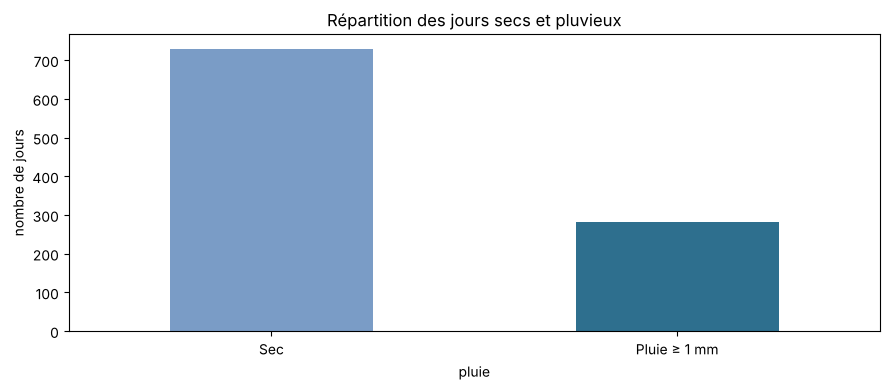

In [12]:
jours["date"] = pd.to_datetime(jours["date"])
jours["pluie"] = (jours["pluie_mm"] >= SEUIL_PLUIE_MM).astype(int)

taux = jours["pluie"].mean()
print(f"Jours de pluie : {taux:.1%}  |  jours secs : {1 - taux:.1%}")

jours["pluie"].map({0: "Sec", 1: "Pluie ≥ 1 mm"}).value_counts().plot(kind="bar", color=["#7A9CC6", "#2E6F8E"], rot=0)
plt.title("Répartition des jours secs et pluvieux")
plt.ylabel("nombre de jours")
plt.tight_layout()
plt.savefig("figures/repartition_cible.png", dpi=150)
plt.show()

**Lecture** : les classes sont déséquilibrées (moins de jours de pluie que de jours secs). C'est
pourquoi le modèle utilise `class_weight="balanced"` et pourquoi l'accuracy seule ne suffit pas :
on regarde aussi le rappel et le F1-score.

Jours sans pluie (0 mm) : 60.9%


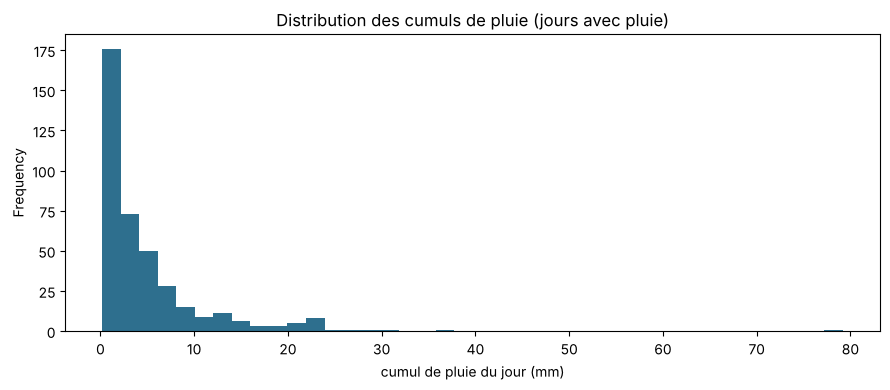

count    1006.00
mean        1.88
std         4.93
min         0.00
25%         0.00
50%         0.00
75%         1.40
max        79.20
Name: pluie_mm, dtype: float64

In [13]:
pluie = jours["pluie_mm"].dropna()
print(f"Jours sans pluie (0 mm) : {(pluie == 0).mean():.1%}")
pluie[pluie > 0].plot(kind="hist", bins=40, color="#2E6F8E")
plt.xlabel("cumul de pluie du jour (mm)")
plt.title("Distribution des cumuls de pluie (jours avec pluie)")
plt.tight_layout()
plt.show()
pluie.describe().round(2)

### 4.2 Les variables météo

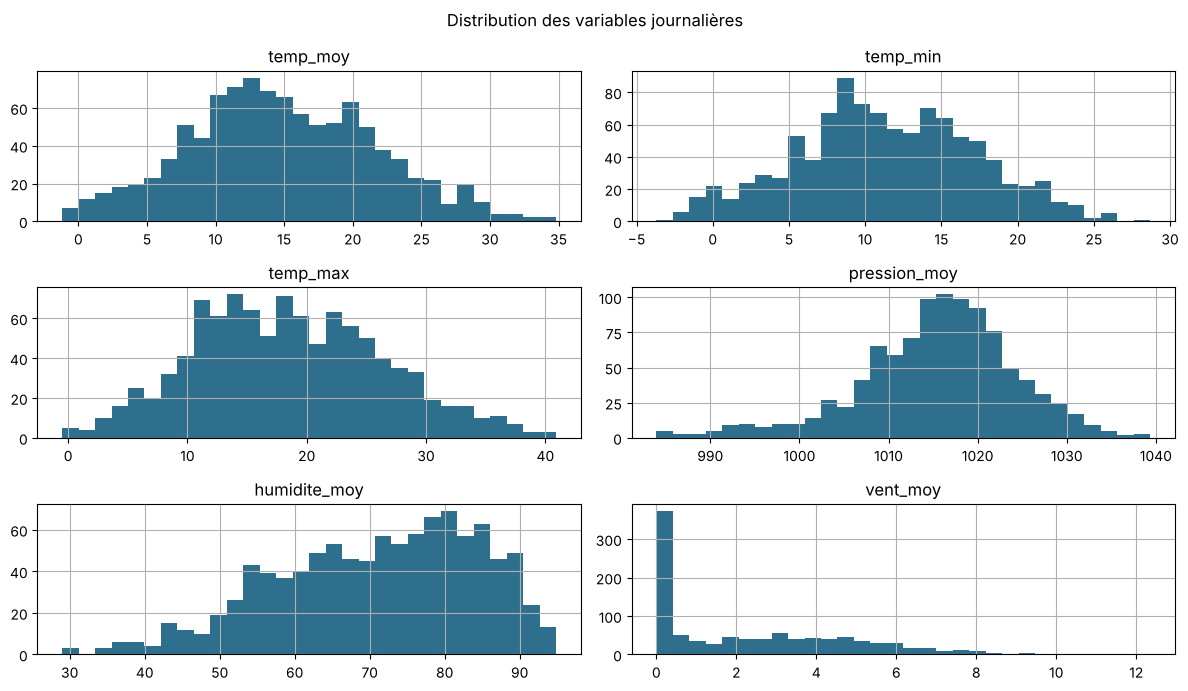

,temp_moy,temp_min,temp_max,pression_moy,humidite_moy,vent_moy
count,1011.0,1011.0,1011.0,1011.0,1011.0,1011.0
mean,14.8,11.3,18.5,1015.4,70.9,2.4
std,6.8,5.9,7.9,8.9,13.4,2.4
min,-1.2,-3.7,-0.5,983.9,29.0,0.0
25%,10.2,7.5,12.6,1010.5,61.3,0.0
50%,14.4,11.2,18.2,1016.2,72.6,1.8
75%,19.6,15.4,24.2,1021.0,81.6,4.2
max,34.8,28.7,40.9,1039.4,94.8,12.4


In [14]:
variables = [c for c in ["temp_moy", "temp_min", "temp_max", "pression_moy", "humidite_moy",
                         "vent_moy", "rafales_max"] if jours[c].notna().any()]
jours[variables].hist(bins=30, figsize=(12, 7), color="#2E6F8E")
plt.suptitle("Distribution des variables journalières")
plt.tight_layout()
plt.show()
jours[variables].describe().round(1)

### 4.3 Saisonnalité

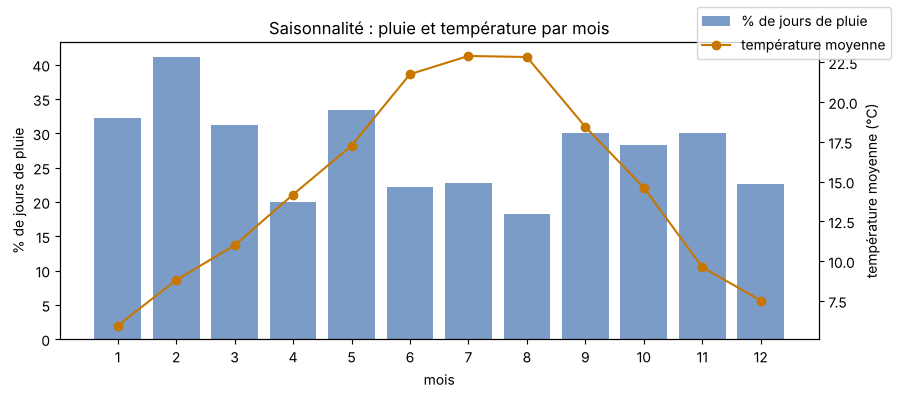

,taux_pluie,temperature
mois,,
1,0.32,5.94
2,0.41,8.81
3,0.31,11.00
4,0.20,14.19
5,0.33,17.26
6,0.22,21.75
7,0.23,22.90
8,0.18,22.83
9,0.30,18.44


In [15]:
jours["mois"] = jours["date"].dt.month
par_mois = jours.groupby("mois").agg(taux_pluie=("pluie", "mean"), temperature=("temp_moy", "mean"))

fig, ax1 = plt.subplots()
ax1.bar(par_mois.index, par_mois["taux_pluie"] * 100, color="#7A9CC6", label="% de jours de pluie")
ax1.set_xlabel("mois")
ax1.set_ylabel("% de jours de pluie")
ax2 = ax1.twinx()
ax2.plot(par_mois.index, par_mois["temperature"], color="#C77700", marker="o", label="température moyenne")
ax2.set_ylabel("température moyenne (°C)")
ax1.set_xticks(range(1, 13))
plt.title("Saisonnalité : pluie et température par mois")
fig.legend(loc="upper right")
plt.tight_layout()
plt.savefig("figures/saisonnalite.png", dpi=150)
plt.show()
par_mois.round(2)

**Lecture** : la fréquence de la pluie varie selon la saison, ce qui justifie d'ajouter au modèle
des variables de saison (`saison_sin`, `saison_cos`, calculées à partir du jour de l'année).

## 5. Analyse bivariée : qu'est-ce qui annonce la pluie du lendemain ?

Le modèle prédit la pluie du jour J avec les mesures de la **veille** (J-1). On étudie donc le lien
entre chaque variable de la veille et la pluie du jour.

In [16]:
df = preparer(jours[nettoyage.COLONNES_JOUR[1:] + ["date"]])
df = df[df["pluie"] >= 0]
colonnes_utiles = [c for c in COLONNES_MODELE if df[c].notna().any()]
print("Variables disponibles :", colonnes_utiles)
df[colonnes_utiles + ["pluie"]].head()

Variables disponibles : ['temp_moy_veille', 'temp_min_veille', 'temp_max_veille', 'pression_moy_veille', 'humidite_moy_veille', 'vent_moy_veille', 'pluie_mm_veille', 'tendance_pression', 'saison_sin', 'saison_cos']


,temp_moy_veille,temp_min_veille,temp_max_veille,pression_moy_veille,humidite_moy_veille,vent_moy_veille,pluie_mm_veille,tendance_pression,saison_sin,saison_cos,pluie
2024-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.017202,0.999852,1
2024-01-02,9.01,7.2,10.9,1008.21,80.68,4.98,6.0,NaN,0.034398,0.999408,1
2024-01-03,11.63,10.7,12.7,997.50,87.15,9.33,10.0,-10.71,0.051584,0.998669,1
2024-01-04,11.44,9.7,13.3,999.11,81.01,5.81,4.0,1.61,0.068755,0.997634,0
2024-01-05,10.35,8.6,11.8,1005.12,82.75,3.69,0.0,6.01,0.085906,0.996303,0


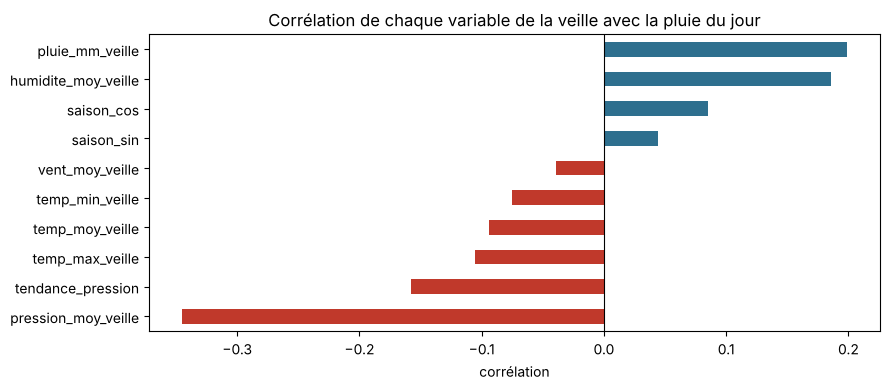

pression_moy_veille   -0.345
tendance_pression     -0.158
temp_max_veille       -0.106
temp_moy_veille       -0.094
temp_min_veille       -0.075
vent_moy_veille       -0.039
saison_sin             0.044
saison_cos             0.085
humidite_moy_veille    0.186
pluie_mm_veille        0.199
Name: pluie, dtype: float64

In [17]:
correlations = df[colonnes_utiles + ["pluie"]].corr()["pluie"].drop("pluie").sort_values()
correlations.plot(kind="barh", color=["#C0392B" if v < 0 else "#2E6F8E" for v in correlations])
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Corrélation de chaque variable de la veille avec la pluie du jour")
plt.xlabel("corrélation")
plt.tight_layout()
plt.savefig("figures/correlations_cible.png", dpi=150)
plt.show()
correlations.round(3)

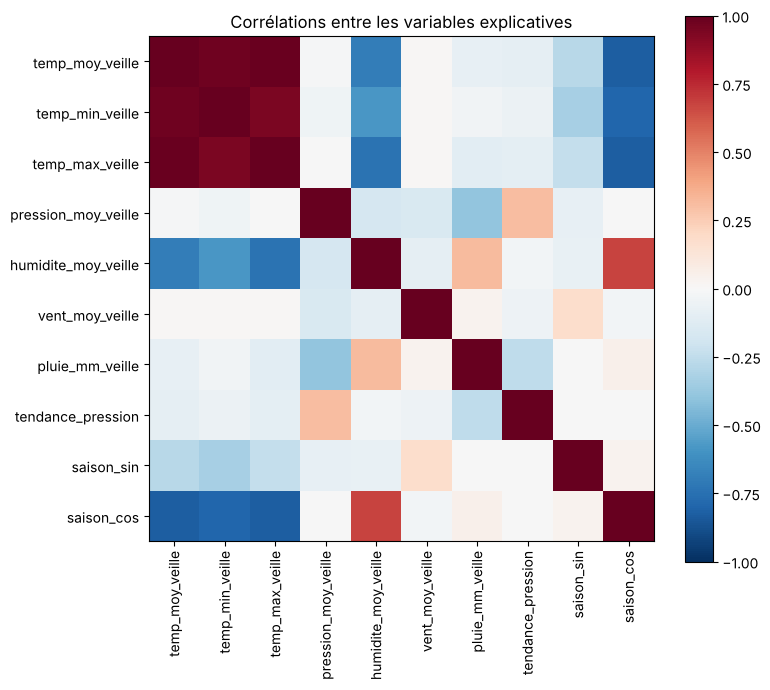

In [18]:
matrice = df[colonnes_utiles].corr()
fig, ax = plt.subplots(figsize=(8, 7))
image = ax.imshow(matrice, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(matrice)))
ax.set_xticklabels(matrice.columns, rotation=90)
ax.set_yticks(range(len(matrice)))
ax.set_yticklabels(matrice.columns)
plt.colorbar(image)
plt.title("Corrélations entre les variables explicatives")
plt.tight_layout()
plt.show()

**Lecture** : les variables très corrélées entre elles (par exemple les trois températures) apportent
une information proche. La régression logistique le supporte bien grâce à la standardisation, et
cela reste un modèle simple et explicable.

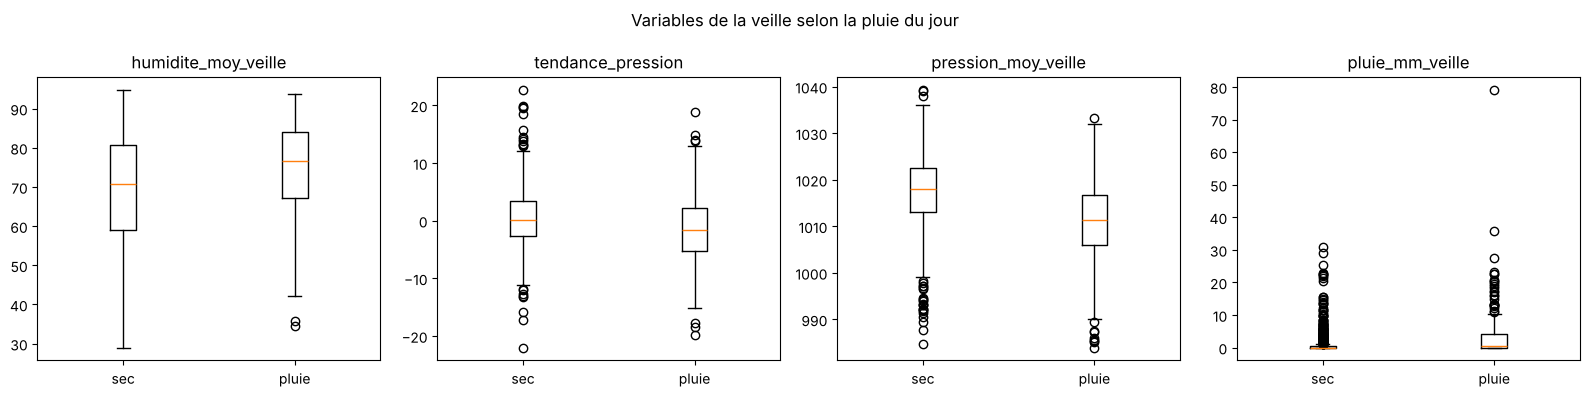

In [19]:
a_comparer = [c for c in ["humidite_moy_veille", "tendance_pression", "pression_moy_veille",
                          "pluie_mm_veille", "temp_moy_veille", "rafales_max_veille"] if c in colonnes_utiles][:4]
fig, axes = plt.subplots(1, len(a_comparer), figsize=(4 * len(a_comparer), 4))
if len(a_comparer) == 1:
    axes = [axes]
for ax, colonne in zip(axes, a_comparer):
    donnees = [df.loc[df["pluie"] == k, colonne].dropna() for k in (0, 1)]
    ax.boxplot(donnees)
    ax.set_xticks([1, 2])
    ax.set_xticklabels(["sec", "pluie"])
    ax.set_title(colonne)
plt.suptitle("Variables de la veille selon la pluie du jour")
plt.tight_layout()
plt.savefig("figures/boxplots_veille.png", dpi=150)
plt.show()

In [20]:
# Persistance : s'il a plu la veille, pleut-il plus souvent le lendemain ?
pluie_veille = (df["pluie_mm_veille"] >= SEUIL_PLUIE_MM).map({True: "pluie la veille", False: "sec la veille"})
(df.groupby(pluie_veille)["pluie"].mean() * 100).round(1).to_frame("% de jours de pluie le lendemain")

,% de jours de pluie le lendemain
pluie_mm_veille,
pluie la veille,45.4
sec la veille,21.2


**Lecture** : ce tableau montre l'effet de « persistance ». C'est la règle de référence que le modèle
doit battre : s'il ne fait pas mieux que « il pleuvra demain s'il a plu aujourd'hui », il n'est pas utile.

## 6. Préparation des variables du modèle

Variables retenues (11) : les 8 mesures de la veille, la tendance de pression sur 24 h et la saison
(sinus et cosinus du jour de l'année, pour que décembre et janvier soient proches).

Choix pour limiter le volume et le calcul (éco-conception) :
- une seule station, uniquement les variables utiles ;
- données journalières plutôt que toutes les 10 minutes ;
- jours gardés si au moins la moitié des variables de la veille sont connues ; les trous restants
  sont complétés par la médiane (calculée sur l'entraînement uniquement, dans le pipeline).

In [21]:
donnees = df[df[COLONNES_MODELE].isna().mean(axis=1) <= 0.5]
print("Jours utilisables :", len(donnees))

# Découpage chronologique : on apprend sur le passé, on teste sur la période la plus récente
coupure = int(len(donnees) * 0.8)
train, test = donnees.iloc[:coupure], donnees.iloc[coupure:]
print("Entraînement :", train.index.min().date(), "->", train.index.max().date(), f"({len(train)} jours)")
print("Test         :", test.index.min().date(), "->", test.index.max().date(), f"({len(test)} jours)")
print(f"Taux de pluie : entraînement {train['pluie'].mean():.1%} | test {test['pluie'].mean():.1%}")

Jours utilisables : 1004
Entraînement : 2024-01-02 -> 2026-04-05 (803 jours)
Test         : 2026-04-06 -> 2026-10-23 (201 jours)
Taux de pluie : entraînement 31.1% | test 14.9%


## 7. Modélisation et évaluation

### 7.1 Entraînement et choix du seuil d'alerte
Pipeline : complétion des trous (médiane) → standardisation → régression logistique avec
rééquilibrage des classes. Le modèle est léger : il s'entraîne en moins d'une seconde sur un processeur.

Le **seuil d'alerte** (probabilité à partir de laquelle on prévient l'agriculteur) est choisi
**uniquement sur les données d'entraînement**, par validation chronologique en 4 blocs : on garde
le seuil qui maximise le F1-score. La période de test n'est jamais utilisée pour ce choix.

In [22]:
import time

seuil_alerte = choisir_seuil_alerte(train)
print("Seuil d'alerte retenu :", seuil_alerte)

modele = nouveau_modele()
debut = time.time()
modele.fit(train[COLONNES_MODELE], train["pluie"])
print(f"Temps d'entraînement : {time.time() - debut:.2f} s")

Seuil d'alerte retenu : 0.4
Temps d'entraînement : 0.02 s


### 7.2 Résultats sur la période de test, comparés à la référence

In [23]:
def scores(vrai, predit, proba=None):
    resultat = {
        "accuracy": accuracy_score(vrai, predit),
        "précision": precision_score(vrai, predit, zero_division=0),
        "rappel": recall_score(vrai, predit, zero_division=0),
        "F1-score": f1_score(vrai, predit, zero_division=0),
    }
    if proba is not None:
        resultat["ROC-AUC"] = roc_auc_score(vrai, proba)
    return resultat

proba = modele.predict_proba(test[COLONNES_MODELE])[:, 1]
predit = (proba >= seuil_alerte).astype(int)
reference = (test["pluie_mm_veille"] >= SEUIL_PLUIE_MM).astype(int)

tableau = pd.DataFrame({
    f"Modèle (seuil {seuil_alerte})": scores(test["pluie"], predit, proba),
    "Modèle (seuil 0,5 par défaut)": scores(test["pluie"], (proba >= 0.5).astype(int), proba),
    "Référence (persistance)": scores(test["pluie"], reference),
}).round(3)
tableau

,Modèle (seuil 0.4),"Modèle (seuil 0,5 par défaut)",Référence (persistance)
accuracy,0.791,0.846,0.821
précision,0.397,0.478,0.400
rappel,0.767,0.367,0.400
F1-score,0.523,0.415,0.400
ROC-AUC,0.835,0.835,NaN


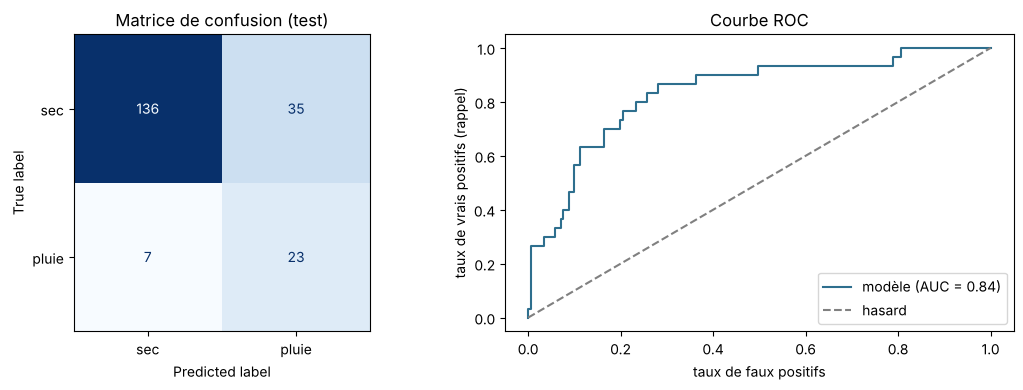

Vrais négatifs : 136 | Faux positifs : 35 | Faux négatifs : 7 | Vrais positifs : 23


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(confusion_matrix(test["pluie"], predit), display_labels=["sec", "pluie"]).plot(
    ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Matrice de confusion (test)")

fpr, tpr, _ = roc_curve(test["pluie"], proba)
axes[1].plot(fpr, tpr, color="#2E6F8E", label=f"modèle (AUC = {roc_auc_score(test['pluie'], proba):.2f})")
axes[1].plot([0, 1], [0, 1], color="grey", linestyle="--", label="hasard")
axes[1].set_xlabel("taux de faux positifs")
axes[1].set_ylabel("taux de vrais positifs (rappel)")
axes[1].set_title("Courbe ROC")
axes[1].legend()
plt.tight_layout()
plt.savefig("figures/evaluation_modele.png", dpi=150)
plt.show()

vn, fp, fn, vp = confusion_matrix(test["pluie"], predit).ravel()
print(f"Vrais négatifs : {vn} | Faux positifs : {fp} | Faux négatifs : {fn} | Vrais positifs : {vp}")

**Lecture** : pour un agriculteur, rater une pluie (faux négatif) coûte plus cher qu'une fausse alerte
(faux positif). On regarde donc en priorité le **rappel** (part des jours de pluie détectés) et on
vérifie que le modèle fait mieux que la référence.

### 7.3 Effet du seuil d'alerte
Pour information, le tableau montre le compromis rappel / précision obtenu sur la période de test
avec différents seuils (le seuil retenu a été choisi avant, sur l'entraînement).

In [25]:
lignes = []
for seuil in [0.3, 0.35, 0.4, 0.45, 0.5, 0.6]:
    p = (proba >= seuil).astype(int)
    lignes.append({"seuil": seuil,
                   "rappel": recall_score(test["pluie"], p, zero_division=0),
                   "précision": precision_score(test["pluie"], p, zero_division=0),
                   "F1-score": f1_score(test["pluie"], p, zero_division=0)})
pd.DataFrame(lignes).round(3)

,seuil,rappel,précision,F1-score
0,0.30,0.933,0.224,0.361
1,0.35,0.900,0.303,0.454
2,0.40,0.767,0.397,0.523
3,0.45,0.567,0.500,0.531
4,0.50,0.367,0.478,0.415
5,0.60,0.233,0.875,0.368


### 7.4 Explicabilité : quelles variables pèsent le plus ?
Les coefficients de la régression logistique (sur données standardisées) indiquent le sens et la force
de l'effet de chaque variable : positif = augmente le risque de pluie.

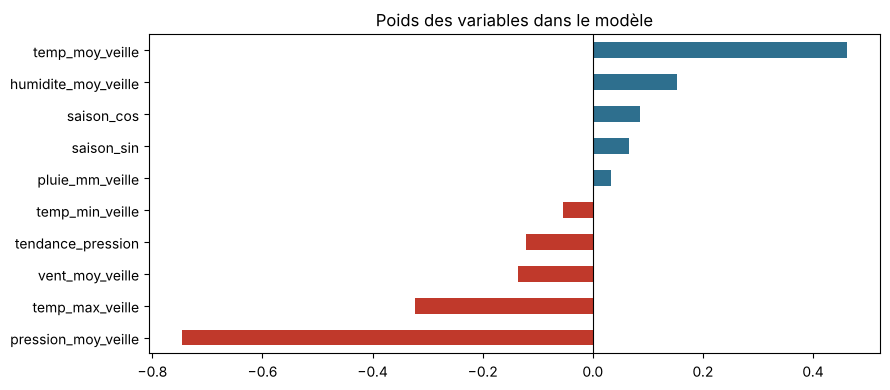

pression_moy_veille   -0.746
temp_max_veille       -0.323
vent_moy_veille       -0.137
tendance_pression     -0.121
temp_min_veille       -0.054
pluie_mm_veille        0.032
saison_sin             0.066
saison_cos             0.085
humidite_moy_veille    0.153
temp_moy_veille        0.461
dtype: float64

In [26]:
imputer = modele.named_steps["simpleimputer"]
noms = [c for c, garde in zip(COLONNES_MODELE, ~pd.isna(imputer.statistics_)) if garde]
coefficients = pd.Series(modele.named_steps["logisticregression"].coef_[0], index=noms).sort_values()
coefficients.plot(kind="barh", color=["#C0392B" if v < 0 else "#2E6F8E" for v in coefficients])
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Poids des variables dans le modèle")
plt.tight_layout()
plt.savefig("figures/coefficients.png", dpi=150)
plt.show()
coefficients.round(3)

### 7.5 Stabilité dans le temps
On vérifie que le modèle n'est pas bon par chance sur une seule période : on l'évalue sur plusieurs
périodes successives (validation chronologique glissante).

In [27]:
from sklearn.model_selection import TimeSeriesSplit

resultats = []
for i, (idx_train, idx_test) in enumerate(TimeSeriesSplit(n_splits=4).split(donnees), start=1):
    a, b = donnees.iloc[idx_train], donnees.iloc[idx_test]
    modele.fit(a[COLONNES_MODELE], a["pluie"])
    p = modele.predict_proba(b[COLONNES_MODELE])[:, 1]
    resultats.append({"bloc": i, "période test": f"{b.index.min().date()} -> {b.index.max().date()}",
                      "rappel": recall_score(b["pluie"], p >= seuil_alerte), "F1-score": f1_score(b["pluie"], p >= seuil_alerte),
                      "ROC-AUC": roc_auc_score(b["pluie"], p)})
stabilite = pd.DataFrame(resultats).round(3)
stabilite

,bloc,période test,rappel,F1-score,ROC-AUC
0,1,2024-08-13 -> 2025-03-01,0.312,0.377,0.720
1,2,2025-03-02 -> 2025-09-17,0.979,0.443,0.719
2,3,2025-09-18 -> 2026-04-06,0.738,0.503,0.648
3,4,2026-04-07 -> 2026-10-23,0.767,0.523,0.835


## 8. Conclusion

- **Données** : 143 923 mesures brutes (une toutes les 10 minutes, de janvier 2024 à octobre 2026),
  agrégées en 1 011 jours nettoyés, dont 1 006 avec une pluie fiable. 27,8 % des jours sont pluvieux (≥ 1 mm).
- **Qualité** : aucun doublon, aucune valeur aberrante ; 15 jours sans mesure sur 1 027. Les rafales ne sont
  pas mesurées par la station : la variable est ignorée.
- **Facteurs principaux** : une pression basse la veille est le signal le plus fort (corrélation −0,35),
  suivie de la pluie et de l'humidité de la veille. S'il a plu la veille, il pleut 45 % du temps le
  lendemain, contre 21 % sinon. La pluie est plus fréquente en hiver (41 % des jours en février) qu'en été (18 % en août).
- **Performance** (période de test, avril à octobre 2026) : avec le seuil d'alerte de 0,40 choisi sur
  l'entraînement, le modèle détecte 77 % des jours de pluie (contre 40 % pour la référence de persistance),
  avec un F1-score de 0,52 (contre 0,40) et un ROC-AUC de 0,84.
- **Limites** : la précision reste modeste (environ 4 alertes sur 10 sont justifiées) ; la période de test
  est estivale et plus sèche que l'entraînement (15 % contre 31 % de jours de pluie) ; une seule station ;
  prévision oui/non sans la quantité. Pistes pour le pilote : capteurs IoT du 75, prévision de quantité
  (RMSE/MAE), réglage du seuil d'alerte avec les agriculteurs.

Le modèle final utilisé par l'API est produit par `python entrainement.py` (mêmes données, mêmes
variables, même pipeline, même seuil).

In [28]:
conn.close()